In [1]:
from keras.datasets import cifar10
from keras.models import Sequential
from keras.layers import Dense, Dropout, Conv2D, MaxPool2D, Flatten
from tensorflow.python.keras.utils.np_utils import to_categorical
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Loading dataset from cifar10

In [2]:
(X_train, Y_train), (X_test, Y_test) = cifar10.load_data()

In [3]:
# # building the input vector from the 32x32 pixels
X_train = X_train.reshape(X_train.shape[0], 32, 32, 3)
X_test = X_test.reshape(X_test.shape[0], 32, 32, 3)
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

In [4]:
# Normalize data for the training
X_train /= 255
X_test /= 255

In [5]:
n_classes = 10
print("Shape before: ", Y_train.shape)
Y_train = to_categorical(Y_train, n_classes)
Y_test = to_categorical(Y_test, n_classes)
print("Shape after: ", Y_train.shape)

Shape before:  (50000, 1)
Shape after:  (50000, 10)


In [6]:
# building a sequential model
model = Sequential()

# convolutional layer
model.add(Conv2D(50, kernel_size=(3,3), strides=(1,1), padding='same', activation='elu', input_shape=(32, 32, 3)))

# convolutional layer
model.add(Conv2D(75, kernel_size=(3,3), strides=(1,1), padding='same', activation='elu'))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Dropout(0.25))

model.add(Conv2D(125, kernel_size=(3,3), strides=(1,1), padding='same', activation='elu'))
model.add(MaxPool2D(pool_size=(2,2)))
model.add(Dropout(0.25))

# flatten output of conv
model.add(Flatten())

# hidden layer
model.add(Dense(500, activation='elu'))
model.add(Dropout(0.4))
model.add(Dense(250, activation='elu'))
model.add(Dropout(0.3))
# output layer
model.add(Dense(10, activation='softmax'))

# compiling the sequential model
model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')

# training the model for 10 epochs
history = model.fit(X_train, Y_train, batch_size=128, epochs=15, validation_data=(X_test, Y_test))

C:\Users\mikeb\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 196s 493ms/step - accuracy: 0.4873 - loss: 1.4607 - val_accuracy: 0.5804 - val_loss: 1.2404
Epoch 2/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 205s 524ms/step - accuracy: 0.6169 - loss: 1.1000 - val_accuracy: 0.6563 - val_loss: 1.0077
Epoch 3/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 276s 559ms/step - accuracy: 0.6529 - loss: 0.9915 - val_accuracy: 0.6739 - val_loss: 0.9490
Epoch 4/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 198s 507ms/step - accuracy: 0.6835 - loss: 0.8977 - val_accuracy: 0.6803 - val_loss: 0.9711
Epoch 5/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 184s 469ms/step - accuracy: 0.7110 - loss: 0.8247 - val_accuracy: 0.6827 - val_loss: 0.9502
Epoch 6/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 14486s 37s/step - accuracy: 0.7384 - loss: 0.7493 - val_accuracy: 0.7277 - val_loss: 0.7807
Epoch 7/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 120s 307ms/step - accuracy: 0.7568 - loss: 0.6903 - val_accuracy: 0.7321 - val_loss: 0.8075
Epoch 8/15
391/391 ━━━━━━━━━━━━━━━━━━━━ 152s 389ms/step - accuracy: 0.7965 -

In [7]:
test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)

print(f"Test accuracy = {test_acc:.3f}")

Test accuracy = 0.768


In [8]:
# Use the trained model to predict the class in test image and compare predicted labels
predictions = model.predict(X_test)

import numpy as np

# Example: predicting first test image
print("Predicted class:", np.argmax(predictions[0]))
print("Actual class:", np.argmax(Y_test[0]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step
Predicted class: 3
Actual class: 3


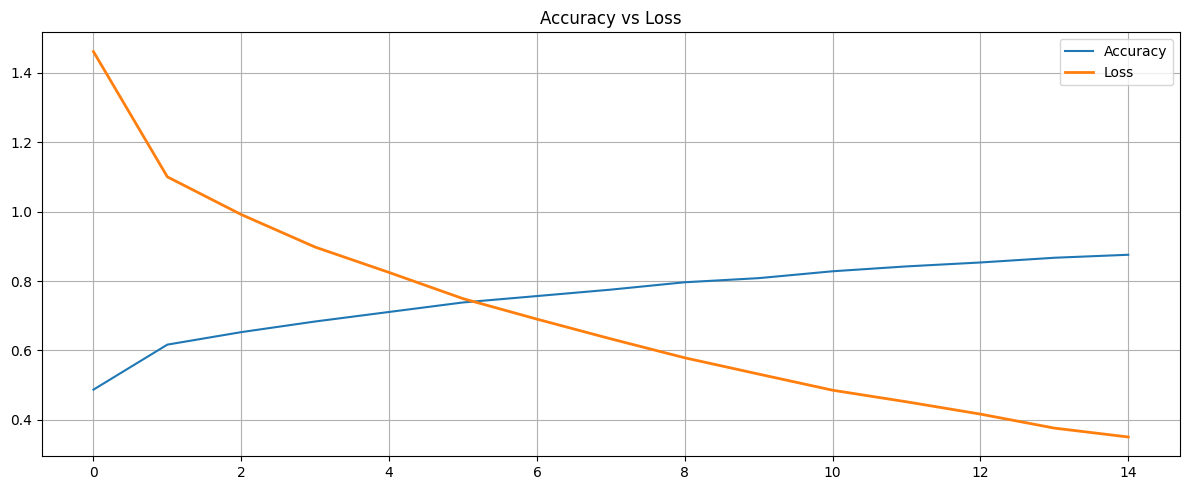

In [9]:
# Using matplotlib to plot and visualize loss and Accuracy during model training.

plt.figure(figsize=(12, 5))
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['loss'], label='Loss', linewidth=2)
plt.legend()
plt.title('Accuracy vs Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

Reference

Zaki Rizvi, M.S. (2020) Learn image classification on 3 datasets using Convolutional Neural Networks (CNN), medium. Available at: https://medium.com/analytics-vidhya/learn-image-classification-on-3-datasets-using-convolutional-neural-networks-cnn-e457d259a2b2 (Accessed: 2026). 

Saha, S. (2026) Image classification using CNN, geeksforgeeks. Available at: https://www.geeksforgeeks.org/profile/Subhajit%20Saha (Accessed: 2026). 